# 03 — Padronização e escalonamento: Adult

Ciência de Dados — Atividade 05: Revisão

Autor: Carlos Gabriel Raposo Landim

Base real: [Adult — UCI](https://archive.ics.uci.edu/dataset/2/adult) e arquivo adult.names incluído

Os arquivos originais estão em `dados/`. As células foram executadas na ordem apresentada. Cada estratégia usa uma cópia; resultados experimentais não são evidência de qualidade preditiva. Em modelos, separar treino/teste antes de ajustar imputadores e escalonadores.

## Importações, nomes das colunas e carregamento

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
DADOS = Path('dados')
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
colunas = ['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
df = pd.read_csv(DADOS/'adult/adult.data',header=None,names=colunas)
original = df.copy(deep=True)
print('Dimensões:',df.shape)
display(pd.DataFrame({'tipo':df.dtypes.astype(str),'ausentes_detectados':df.isna().sum()}))
display(df.head())

Dimensões: (32561, 15)


,tipo,ausentes_detectados
age,int64,0
workclass,str,0
fnlwgt,int64,0
education,str,0
education-num,int64,0
marital-status,str,0
occupation,str,0
relationship,str,0
race,str,0
sex,str,0


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Inspeção das colunas categóricas

In [2]:
categoricas = df.select_dtypes(include=['object','string']).columns.tolist()
for col in categoricas:
    print(col, ':', [repr(v) for v in sorted(df[col].dropna().unique())])

workclass : ["' ?'", "' Federal-gov'", "' Local-gov'", "' Never-worked'", "' Private'", "' Self-emp-inc'", "' Self-emp-not-inc'", "' State-gov'", "' Without-pay'"]
education : ["' 10th'", "' 11th'", "' 12th'", "' 1st-4th'", "' 5th-6th'", "' 7th-8th'", "' 9th'", "' Assoc-acdm'", "' Assoc-voc'", "' Bachelors'", "' Doctorate'", "' HS-grad'", "' Masters'", "' Preschool'", "' Prof-school'", "' Some-college'"]
marital-status : ["' Divorced'", "' Married-AF-spouse'", "' Married-civ-spouse'", "' Married-spouse-absent'", "' Never-married'", "' Separated'", "' Widowed'"]
occupation : ["' ?'", "' Adm-clerical'", "' Armed-Forces'", "' Craft-repair'", "' Exec-managerial'", "' Farming-fishing'", "' Handlers-cleaners'", "' Machine-op-inspct'", "' Other-service'", "' Priv-house-serv'", "' Prof-specialty'", "' Protective-serv'", "' Sales'", "' Tech-support'", "' Transport-moving'"]
relationship : ["' Husband'", "' Not-in-family'", "' Other-relative'", "' Own-child'", "' Unmarried'", "' Wife'"]
race : [

## Padronização de textos e conversão dos marcadores de ausência

,categorias_antes,categorias_padronizadas,categorias_sem_marcadores,ausentes_antes,ausentes_depois,linhas_com_espacos
workclass,9,9,8,0,1836,32561
education,16,16,16,0,0,32561
marital-status,7,7,7,0,0,32561
occupation,15,15,14,0,1843,32561
relationship,6,6,6,0,0,32561
race,5,5,5,0,0,32561
sex,2,2,2,0,0,32561
native-country,42,42,41,0,583,32561
income,2,2,2,0,0,32561


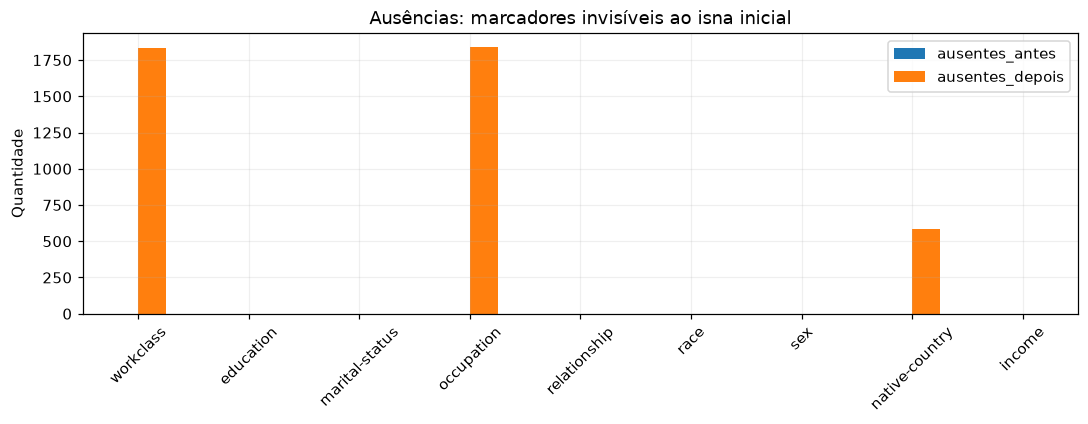

In [3]:
padronizado = df.copy()
for col in categoricas:
    padronizado[col] = df[col].astype('string').str.strip().str.casefold()
limpo = padronizado.copy()
for col in categoricas:
    limpo[col] = padronizado[col].replace({'?':pd.NA, '':pd.NA})
comparacao = pd.DataFrame({'categorias_antes':df[categoricas].nunique(),'categorias_padronizadas':padronizado[categoricas].nunique(),'categorias_sem_marcadores':limpo[categoricas].nunique(),'ausentes_antes':df[categoricas].isna().sum(),'ausentes_depois':limpo[categoricas].isna().sum(),'linhas_com_espacos':pd.Series({col:df[col].ne(df[col].str.strip()).sum() for col in categoricas})})
display(comparacao)
comparacao[['ausentes_antes','ausentes_depois']].plot.bar(rot=45,title='Ausências: marcadores invisíveis ao isna inicial')
plt.ylabel('Quantidade'); plt.tight_layout(); plt.show()
assert df.equals(original)
assert not limpo[categoricas].eq('?').any().any()

A capitalização foi uniformizada para consistência, sem fundir categorias com significados diferentes. A tabela permite distinguir uma simples mudança na escrita da remoção do marcador “?”. As ausências reveladas são preservadas; não faço uma imputação categórica silenciosa.

## Escalonamento — Min-Max, Z-score e robusto
Incluo todas as colunas numéricas para comparar matematicamente as técnicas, sem afirmar que todas devam entrar em um modelo. StandardScaler usa desvio-padrão populacional; a comparação usa ddof=0 para corresponder.

Fração capital-gain = 0: 0.9167


min           max        media  desvio_populacional      mediana          IQR
tecnica  variavel                                                                                            
Original age                17.0000  9.000000e+01      38.5816              13.6402      37.0000      20.0000
         fnlwgt          12285.0000  1.484705e+06  189778.3665          105548.3569  178356.0000  119224.0000
         education-num       1.0000  1.600000e+01      10.0807               2.5727      10.0000       3.0000
         capital-gain        0.0000  9.999900e+04    1077.6488            7385.1787       0.0000       0.0000
         capital-loss        0.0000  4.356000e+03      87.3038             402.9540       0.0000       0.0000
         hours-per-week      1.0000  9.900000e+01      40.4375              12.3472      40.0000       5.0000
Min-Max  age                 0.0000  1.000000e+00       0.2956               0.1869       0.2740       0.2740
         fnlwgt              0.0000  1.000000e+00       0.1205               0.0717       0.1128       0.0810
         education-num       0.0000  1.000000e+00       0.6054               0.1715       0.6000       0.2000
         capital-gain        0.0000  1.000000e+00       0.0108               0.0739       0.0000       0.0000
         capital-loss        0.0000  1.000000e+00       0.0200               0.0925       0.0000       0.0000
         hours-per-week      0.0000  1.000000e+00       0.4024               0.1260       0.3980       0.0510
Z-score  age                -1.5822  3.769600e+00      -0.0000               1.0000      -0.1160       1.4663
         fnlwgt             -1.6816  1.226860e+01      -0.0000               1.0000      -0.1082       1.1296
         education-num      -3.5297  2.300800e+00       0.0000               1.0000      -0.0314       1.1661
         capital-gain       -0.1459  1.339460e+01       0.0000               1.0000      -0.1459       0.0000
         capital-loss       -0.2167  1.059350e+01      -0.0000               1.0000      -0.2167       0.0000
         hours-per-week     -3.1940  4.743000e+00      -0.0000               1.0000      -0.0354       0.4049
Robusto  age                -1.0000  2.650000e+00       0.0791               0.6820       0.0000       1.0000
         fnlwgt             -1.3929  1.095710e+01       0.0958               0.8853       0.0000       1.0000
         education-num      -3.0000  2.000000e+00       0.0269               0.8576       0.0000       1.0000
         capital-gain        0.0000  9.999900e+04    1077.6488            7385.1787       0.0000       0.0000
         capital-loss        0.0000  4.356000e+03      87.3038             402.9540       0.0000       0.0000
         hours-per-week     -7.8000  1.180000e+01       0.0875               2.4694       0.0000       1.0000

,min,max,media,desvio_populacional,mediana,IQR
tecnica,,,,,,
Original,0.00000,99999.000000,1.077649e+03,7385.178677,0.00000,0.0
Min-Max,0.00000,1.000000,1.077660e-02,0.073853,0.00000,0.0
Z-score,-0.14592,13.394578,5.237255e-18,1.000000,-0.14592,0.0
Robusto,0.00000,99999.000000,1.077649e+03,7385.178677,0.00000,0.0


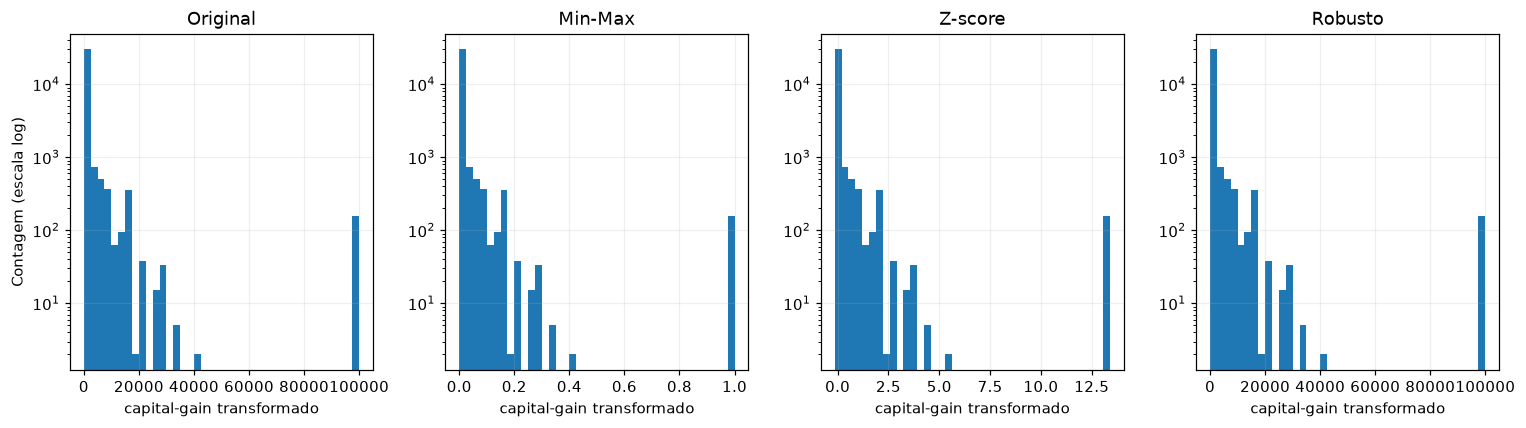

In [4]:
numericas = limpo.select_dtypes(include='number').columns.tolist()
escalas = {'Original':limpo[numericas].copy()}
escalonadores = {'Min-Max':MinMaxScaler(),'Z-score':StandardScaler(),'Robusto':RobustScaler()}
for nome,transformador in escalonadores.items():
    escalas[nome] = pd.DataFrame(transformador.fit_transform(limpo[numericas]),columns=numericas,index=limpo.index)
estatisticas = pd.concat({nome:pd.DataFrame({'min':base.min(),'max':base.max(),'media':base.mean(),'desvio_populacional':base.std(ddof=0),'mediana':base.median(),'IQR':base.quantile(.75)-base.quantile(.25)}) for nome,base in escalas.items()},names=['tecnica','variavel'])
display(estatisticas.round(4))
print('Fração capital-gain = 0:', round((df['capital-gain']==0).mean(),4))
display(estatisticas.xs('capital-gain',level='variavel'))
fig,axs = plt.subplots(1,4,figsize=(14,4))
for ax,(nome,base) in zip(axs,escalas.items()):
    ax.hist(base['capital-gain'],bins=40)
    ax.set(title=nome,xlabel='capital-gain transformado',yscale='log')
axs[0].set_ylabel('Contagem (escala log)'); plt.tight_layout(); plt.show()
estatisticas.to_csv(RESULTADOS/'03_escalonamento.csv')
assert all(np.isfinite(base.to_numpy()).all() for base in escalas.values())

## Respostas às perguntas de reflexão
1. isna reconhece sentinelas de ausência, não todo texto que significa “desconhecido”. Aqui “ ?” era uma string válida: retirar espaços e converter o marcador revela lacunas em workclass, occupation e native-country.
2. capital-gain tem concentração em zero e cauda positiva. Min-Max comprime quase todos os valores perto de zero porque o máximo é muito alto; Z-score também usa média e desvio influenciados pela cauda. O caso mais problemático para a promessa de escala robusta é o IQR igual a zero: RobustScaler evita divisão por zero substituindo a escala nula por 1. Com mediana zero, os ganhos continuam na escala original, como se verifica no máximo e no desvio da tabela. Portanto, “robusto” não significa resolver automaticamente uma variável com muitos zeros. Consideraria um indicador ganho_positivo e log1p para os valores, conforme o modelo.
3. fnlwgt é o peso final de amostragem, ligado à representatividade da observação, conforme adult.names. Não é quantidade física individual nem identificador. Em uma análise populacional, consideraria seu uso como peso conforme a metodologia da pesquisa, em vez de tratá-lo automaticamente como preditor. education-num é ordinal; modelos de árvore não exigem a mesma preparação de distância que KNN. A técnica e o objetivo determinam o que escalonar.
4. Ajustar transformações no conjunto completo é aceitável nesta comparação descritiva, mas em avaliação preditiva fit deve usar apenas treino, seguido de transform em validação/teste.

Referências: [adult.names](https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names), [RobustScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html).

## Síntese dos resultados executados

Foram reveladas 1.836 ausências em workclass, 1.843 em occupation e 583 em native-country. Em capital-gain, 91,67% dos registros são zero; o máximo após RobustScaler continua 99.999 por causa do IQR nulo. Esses resultados sustentam a necessidade de tratar concentração em zero separadamente.